# AP 155 Lab Exercise
---
## Exercise 8: Interpolation

_Instructions_:
- **Report figures:** Compare the original data with interpolated reconstructions. Include the synthetic sine example and the sampled real-world dataset, if available. For the real-world dataset, compare sampling levels of 50%, 30%, 10%, and 5%.
- **Report discussion:** Explain how the choice of interpolator and sampling level affects the reconstruction. Discuss limitations, including behavior outside the sampled domain.
- **Code:** Complete the code and ensure it is functional, readable, and efficient. Include concise Markdown documentation highlighting the critical steps.

### Student Information
- _Full Name (Last Name, First Name)_: Botron, Christan Jake
- _Student No._: 2024-10168
- _Section_: THU-TX-1

### Grading Information (c/o Lab Instructor)

| Criteria | Score | Subtotal |
| --- | --- | --- |
| Report figures | XX | 20 |
| Report discussion | XX | 20 |
| Code readability | XX | 20 |
| Code efficiency | XX | 20 |
| Code appropriateness | XX | 20 |
| **TOTAL** | XXX | 100 |

_Date and Time Scored (MM/DD/YYYY HH:MM AM/PM):_

---
## Section 1: Report

### Report figures

<img src="Figures/figure1.png" alt="Figure 1" width=90%>

**Figure 1. Synthetic data interpolation.** Comparison of the noisy synthetic sine data against the linear, quadratic, and cubic interpolated reconstructions across the bounded domain.

<img src="Figures/figure2.png" alt="Figure 2" width=90%>

**Figure 2. Real-world data reconstruction.** Linear interpolation of the Dow Jones dataset, demonstrating signal degradation across sampling retention levels of 50%, 30%, 10%, and 5%.

### Report discussion

For the synthetic sine data, higher-order polynomial interpolations (quadratic and cubic) reconstruct the underlying function more accurately than the linear method. This is because linear interpolation creates rigid, jagged connections between noisy points, while polynomial interpolation methods provide a smoother and continuous curve that better approximates the true harmonic nature of the signal. However, a major limitation is that these interpolators strictly require bounded inputs, and they cannot reliably extrapolate outside the sampled domain bounds. On the topic of sampling fraction, as the sampling fraction decreases (specifically from 50% down to 5% in this context), the reconstruction quality of the real-world Dow Jones dataset rapidly degrades. Lower sampling levels fail to capture high-frequency market volatility, resulting in aliasing and a loss of critical structural features. Furthermore, when applying higher-order interpolators to these sparse regions, severe visual artifacts emerge. The polynomial fits drastically overshoot the actual boundaries between sparse, rapidly changing observations, creating artificial peaks and valleys that misrepresent the original data. 

### Other comments
- I have no other comments.

---
## Section 2: Code

In [10]:
import numpy as np
import matplotlib.pyplot as plt
from scipy import interpolate
from pathlib import Path

rng = np.random.default_rng(42)
x = np.linspace(0,2*np.pi, 100)
noise = rng.normal(loc=0.0, scale=0.1, size=x.shape)

### Problem 1: Interpolation of synthetic data

Generate random samples from a known sine function, then compare several interpolation methods. The interpolators only reconstruct values within the sampled domain; they should not be treated as reliable extrapolators outside it.

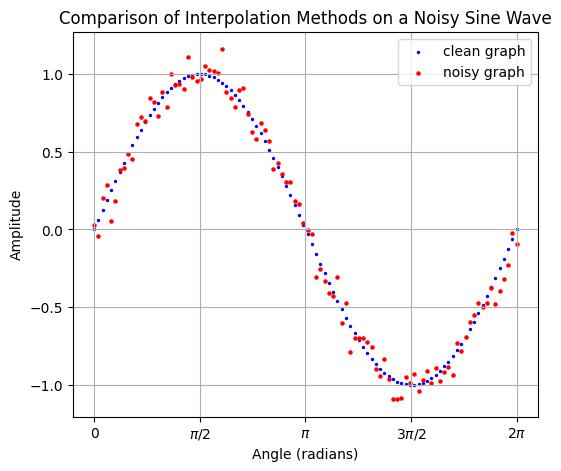

In [33]:
y_clean = np.sin(x)
y_sample = y_clean + noise

plt.figure(figsize=(6, 5))
plt.scatter(x, y_clean, label='clean graph', color='blue', s=2)
plt.scatter(x, y_sample, label='noisy graph', color='red', s=5)
plt.grid()
plt.xticks([0, np.pi / 2, np.pi, 3 * np.pi / 2, 2 * np.pi], [0, r'$\pi/2$', r'$\pi$', r'$3\pi/2$', r'$2\pi$'])
plt.legend()

plt.title("Comparison of Interpolation Methods on a Noisy Sine Wave")
plt.xlabel("Angle (radians)")
plt.ylabel("Amplitude")

plt.show()

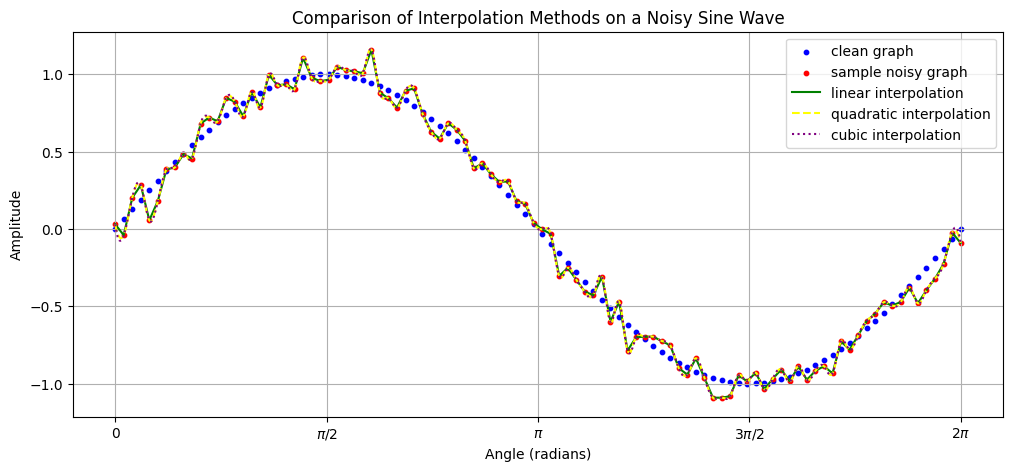

In [29]:
x_test = np.linspace(0,2*np.pi, 1000)

f_linear = interpolate.interp1d(x, y_sample, kind='linear')
f_quad = interpolate.interp1d(x, y_sample, kind='quadratic')
f_cubic = interpolate.interp1d(x, y_sample, kind='cubic')

plt.figure(figsize=(12, 5))
plt.scatter(x, y_clean, label='clean graph', color='blue', s=10)
plt.scatter(x, y_sample, label='sample noisy graph', color='red', s=10)

plt.plot(x_test, f_linear(x_test), label='linear interpolation', color='green')
plt.plot(x_test, f_quad(x_test), label='quadratic interpolation', color='yellow', linestyle='--')
plt.plot(x_test, f_cubic(x_test), label='cubic interpolation', color='purple', linestyle=':')

plt.grid()
plt.xticks([0, np.pi / 2, np.pi, 3 * np.pi / 2, 2 * np.pi], [0, r'$\pi/2$', r'$\pi$', r'$3\pi/2$', r'$2\pi$'])
plt.legend()
plt.title("Comparison of Interpolation Methods on a Noisy Sine Wave")
plt.xlabel("Angle (radians)")
plt.ylabel("Amplitude")

#plt.xlim(np.pi, 3*np.pi/2

plt.savefig("Figures/figure1.png", dpi=300, bbox_inches='tight')
plt.show()

### Problem 2: Interpolation of real-world data

Load the Dow Jones time-series dataset, randomly retain a specified fraction of observations, and compare the reconstructed curve with the original series. The sampling fractions are 50%, 30%, 10%, and 5%. 

In [13]:
# !wget --quiet https://www-personal.umich.edu/~mejn/cp/data/dow.txt

In [14]:
# load the dataset; download it first if needed
# path is https://websites.umich.edu/~mejn/cp/data/dow.txt

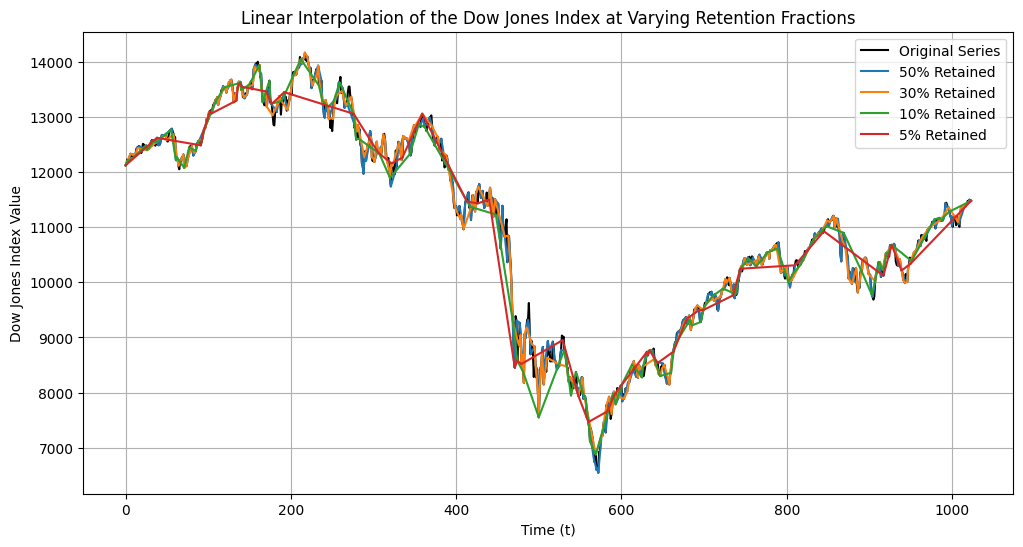

In [30]:
dow = np.loadtxt('dow.txt')
x_dow = np.arange(len(dow))
fractions = [0.50, 0.30, 0.10, 0.05]

plt.figure(figsize=(12, 6))
plt.plot(x_dow, dow, label='Original Series', color='black')

for obs_frac in fractions:
    num_samples = int(len(dow) * obs_frac)

    sampled_indices = rng.choice(len(dow), size=num_samples, replace=False) #select random indices for the sample
    
    #boundaries
    if 0 not in sampled_indices:
        sampled_indices[0] = 0
    if len(dow) - 1 not in sampled_indices:
        sampled_indices[1] = len(dow) - 1

    sampled_indices = np.sort(sampled_indices) #sort to account for the rng.choice function
    
    #interpolate
    x_sampled = x_dow[sampled_indices]
    y_sampled = dow[sampled_indices]
    
    f_linear = interpolate.interp1d(x_sampled, y_sampled, kind='linear')
    y_reconstructed = f_linear(x_dow)
    
    plt.plot(x_dow, y_reconstructed, label=f'{int(obs_frac*100)}% Retained')

plt.title('Linear Interpolation of the Dow Jones Index at Varying Retention Fractions')
plt.xlabel('Time (t)')
plt.ylabel('Dow Jones Index Value')
plt.legend()
plt.grid()

plt.savefig("Figures/figure2.png", dpi=300, bbox_inches='tight')
plt.show()

### Problem 3: Compare interpolation methods on the sampled real-world data

Use a single sampling fraction to compare linear, quadratic, and cubic interpolation. Higher-order interpolation can produce smoother curves, but it can also overshoot between sparse or rapidly changing observations.

In [19]:
#copy pasted from part 2; separated so the plot below is fixed
obs_frac = 0.30
num_samples = int(len(dow) * obs_frac)
sampled_indices = rng.choice(len(dow), size=num_samples, replace=False)

if 0 not in sampled_indices:
    sampled_indices[0] = 0
if len(dow) - 1 not in sampled_indices:
    sampled_indices[1] = len(dow) - 1

sampled_indices = np.sort(sampled_indices)

x_sampled = x_dow[sampled_indices]
y_sampled = dow[sampled_indices]

#---------------------------------------#

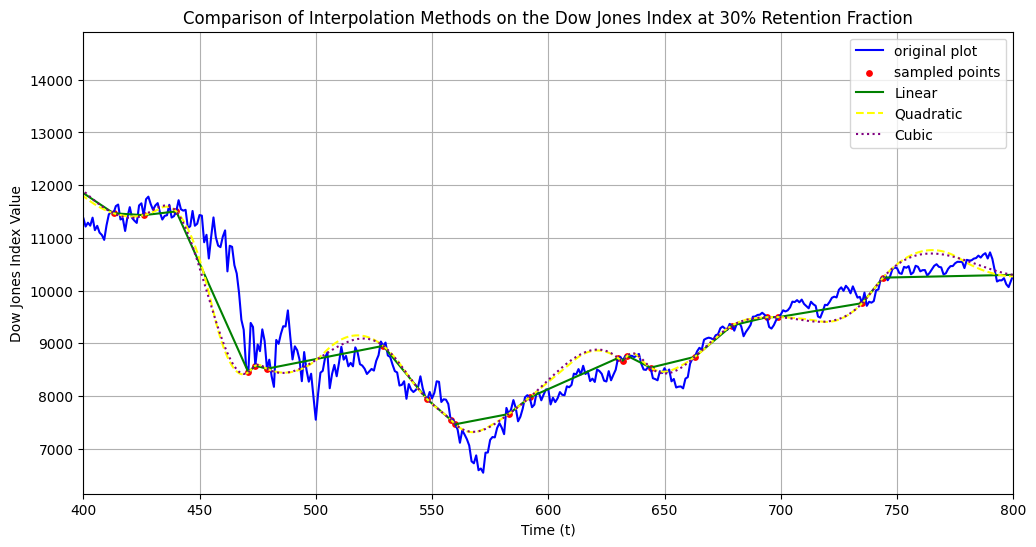

In [32]:
f_linear = interpolate.interp1d(x_sampled, y_sampled, kind='linear')
f_quad = interpolate.interp1d(x_sampled, y_sampled, kind='quadratic')
f_cubic = interpolate.interp1d(x_sampled, y_sampled, kind='cubic')

plt.figure(figsize=(12, 6))

plt.plot(x_dow, dow, label='original plot', color='blue')
plt.scatter(x_sampled, y_sampled, color='red', s=15, label='sampled points')

plt.plot(x_dow, f_linear(x_dow), label='Linear', color='green')
plt.plot(x_dow, f_quad(x_dow), label='Quadratic', color='yellow', linestyle='--')
plt.plot(x_dow, f_cubic(x_dow), label='Cubic', color='purple', linestyle=':')

plt.title('Comparison of Interpolation Methods on the Dow Jones Index at 30% Retention Fraction')
plt.xlabel('Time (t)')
plt.ylabel('Dow Jones Index Value')
plt.legend()
plt.grid()

plt.xlim(400, 800) #edit me; for zooming in to better see the interpolation

plt.show()

### Problem  code summary


For Problem 1, noisy synthetic data was generated from a sine function and applied linear, quadratic, and cubic interpolators to reconstruct the curve within its original bounds. For Problem 2, the Dow Jones dataset was sampled from 50% to 5% retention to demonstrate how linear signal reconstruction degrades as data becomes sparser. Finally, for Problem 3, by locking the sampling fraction at 30% and isolating a specific segment, it was demonstrated how higher-order polynomial interpolations severely overshoot the actual curve between sparse data points.

---